# Diversity of the explored chemical space

**Clustered parent selection**, ten seeds per strategy.

Each cycle picks the molecules to modify with diversity-based clustering
(`clustering=True`) instead of taking the plain top scorers. Otherwise the settings match
the earlier runs: 100 starting molecules drawn at random from the library, 20 cycles,
50 oracle queries per cycle.

Same analyses as `results_diversity.ipynb`, read from
`Results/init100_clustered_parents_10seeds`. Every plot shows all ten runs, so the spread
between seeds is visible.


In [52]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from rdkit import RDLogger

import analysis_utils as an
import docking_utils

RDLogger.DisableLog("rdApp.*")
sns.set_context("talk")

In [53]:
HERE = Path(_dh[-1])
RESULTS_FOLDER = HERE / ".." / "Results" / "all_seeds_2026-10-28-16-00"
FIGURE_FOLDER = RESULTS_FOLDER
AFFINITY_FILE = HERE / ".." / "data" / "recombination_library" / "predictions_skip_hyde_random_split_large.csv"

N_CYCLES = 20
TOP_NUMS = [50, 100, 500]
STRATEGIES = ["greedy", "diverse", "random"]
COLORS = {"greedy": "C0", "diverse": "C1", "random": "grey"}
SUBPOCKETS = an.SUBPOCKETS          # AP, FP, GA, SE

In [54]:
def load_runs(folder):
    """{strategy: {seed: DataFrame}} for every result file in the folder."""
    runs = {}
    for path in sorted(Path(folder).glob("*.csv")):
        parts = path.stem.split("_")
        # skip anything that is not a result file, e.g. a table saved beside them
        if "kinodata" not in parts or not any(p.startswith("seed") for p in parts):
            continue
        strategy = parts[parts.index("kinodata") + 1]
        seed = int(next(p for p in parts if p.startswith("seed"))[4:])
        runs.setdefault(strategy, {})[seed] = pd.read_csv(path)
    return runs


runs = load_runs(RESULTS_FOLDER)
affinities = docking_utils.read_affinities(str(AFFINITY_FILE))
sorted_affs = an.sort_affinities(affinities)

for strategy, by_seed in runs.items():
    print(f"{strategy:<9} {len(by_seed)} runs, "
          f"{sum(len(df) for df in by_seed.values())} molecules in total")

diverse   10 runs, 5065 molecules in total
greedy    10 runs, 7688 molecules in total
random    10 runs, 7731 molecules in total


In [55]:
def per_seed_curves(metric):
    """{strategy: array of shape (runs, cycles)} for a function taking one DataFrame."""
    return {strategy: np.array([metric(df) for _, df in sorted(by_seed.items())])
            for strategy, by_seed in runs.items()}


def plot_curves(curves, ylabel, ax=None, show_runs=True):
    """Thin line per run, thick line for the mean, shaded band for one standard deviation."""
    ax = ax or plt.gca()
    for strategy in STRATEGIES:
        values = curves[strategy]
        x = range(values.shape[1])
        if show_runs:
            for row in values:
                ax.plot(x, row, color=COLORS[strategy], alpha=0.3, linewidth=1.5)
        mean, sd = values.mean(axis=0), values.std(axis=0, ddof=1)
        ax.plot(x, mean, color=COLORS[strategy], linewidth=4, label=strategy)
        ax.fill_between(x, mean - sd, mean + sd, color=COLORS[strategy], alpha=0.12)
    ax.set_xlabel("Active learning cycle")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1)
    return ax

## Overall molecular diversity

One minus the mean pairwise Tanimoto similarity of the molecules selected in each cycle.

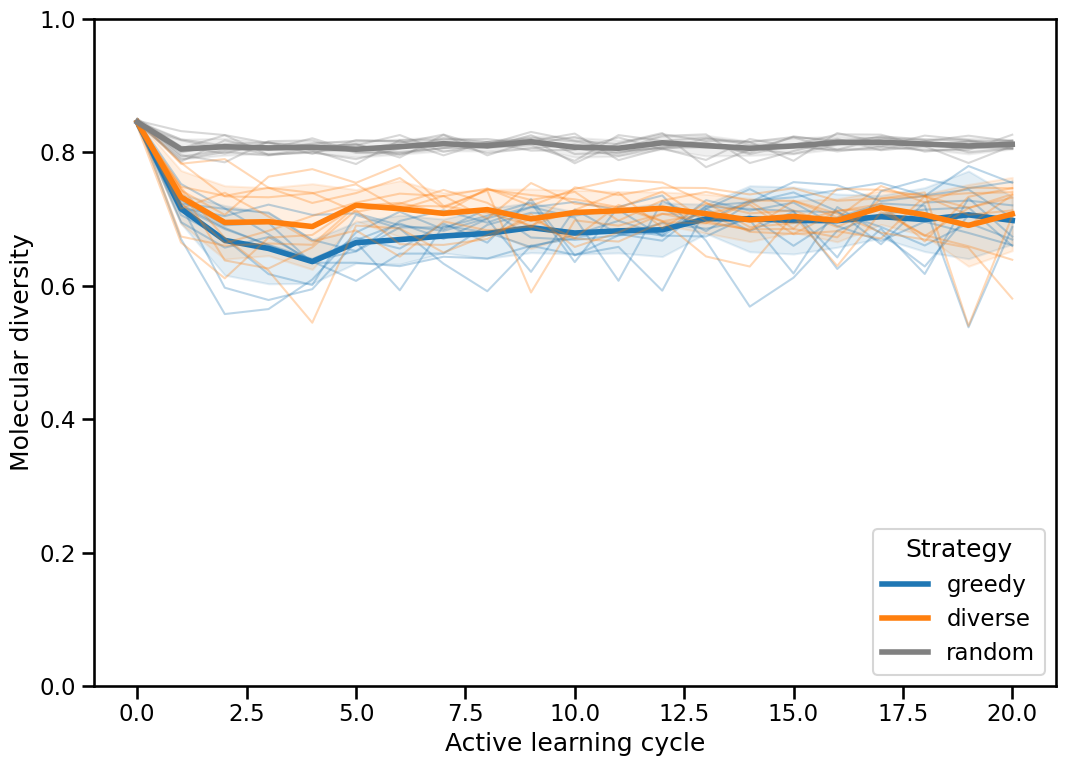

,final,sd
diverse,0.708,0.055
greedy,0.698,0.036
random,0.812,0.007


In [56]:
molecular = per_seed_curves(
    lambda df: an.molecular_diversity(an.add_fingerprints(df), N_CYCLES)
)

fig, ax = plt.subplots(figsize=(11, 8))
plot_curves(molecular, "Molecular diversity", ax)
ax.legend(title="Strategy", loc="lower right")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "molecular_diversity_clustered10.svg", format="svg")
plt.show()

pd.DataFrame({s: {"final": v[:, -1].mean(), "sd": v[:, -1].std(ddof=1)}
              for s, v in molecular.items()}).T.round(3)

## Fragment diversity

Share of all fragments in the scored space that have been seen up to each cycle.

356 distinct fragments in the scored space


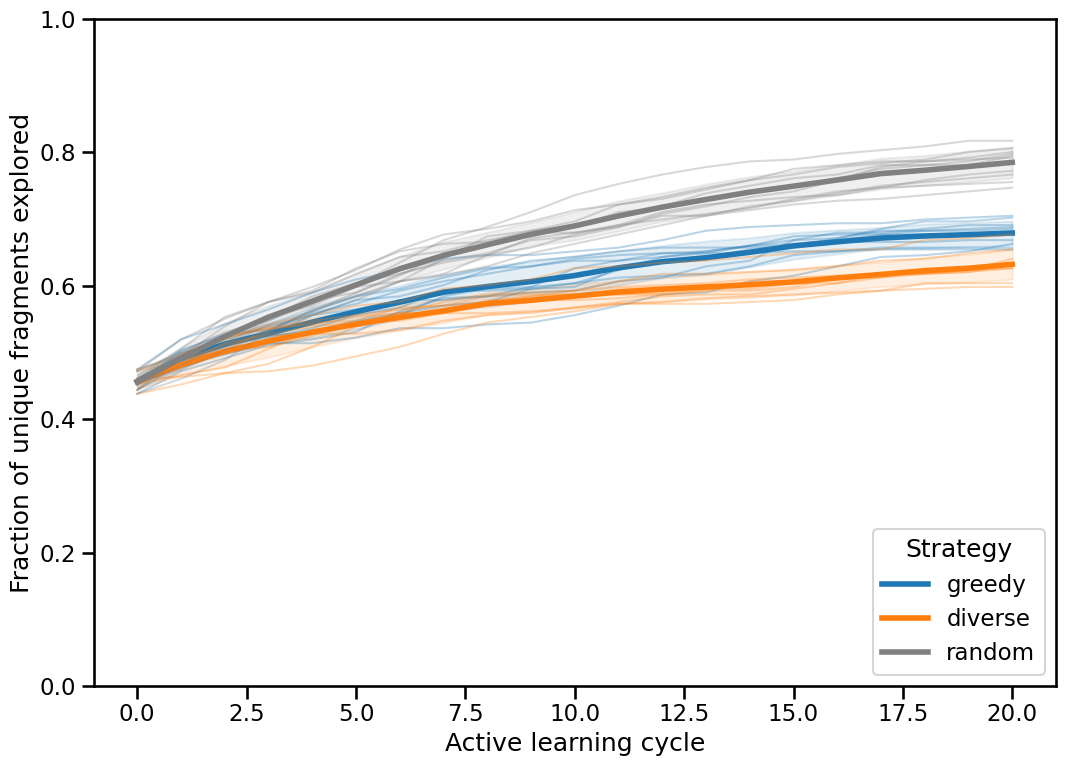

,final,sd
diverse,0.632,0.023
greedy,0.679,0.018
random,0.785,0.023


In [57]:
total_fragments = an.count_total_fragments(affinities)
print(f"{total_fragments} distinct fragments in the scored space")

fragment = per_seed_curves(lambda df: an.fragment_diversity(df, total_fragments, N_CYCLES))

fig, ax = plt.subplots(figsize=(11, 8))
plot_curves(fragment, "Fraction of unique fragments explored", ax)
ax.legend(title="Strategy", loc="lower right")
plt.tight_layout()
plt.savefig(FIGURE_FOLDER / "fragment_diversity_clustered10.svg", format="svg")
plt.show()

pd.DataFrame({s: {"final": v[:, -1].mean(), "sd": v[:, -1].std(ddof=1)}
              for s, v in fragment.items()}).T.round(3)

## Subpocket specific fragment diversity

The same measure split by subpocket. Points are the mean across the five runs, bars one
standard deviation.

In [58]:
total_per_subpocket = an.count_total_fragments_per_subpocket(affinities)
print(dict(zip(SUBPOCKETS, total_per_subpocket)))

subpocket_curves = {}   # strategy -> array (runs, subpockets, cycles)
selected_fragments = {} # strategy -> list over runs of [fragments per subpocket]
for strategy, by_seed in runs.items():
    per_run, frags = [], []
    for _, df in sorted(by_seed.items()):
        diversity, seen = an.fragment_diversity_per_subpocket(df, total_per_subpocket, N_CYCLES)
        per_run.append(diversity)
        frags.append(seen)
    subpocket_curves[strategy] = np.array(per_run)
    selected_fragments[strategy] = frags

{'AP': 98, 'FP': 94, 'GA': 73, 'SE': 91}


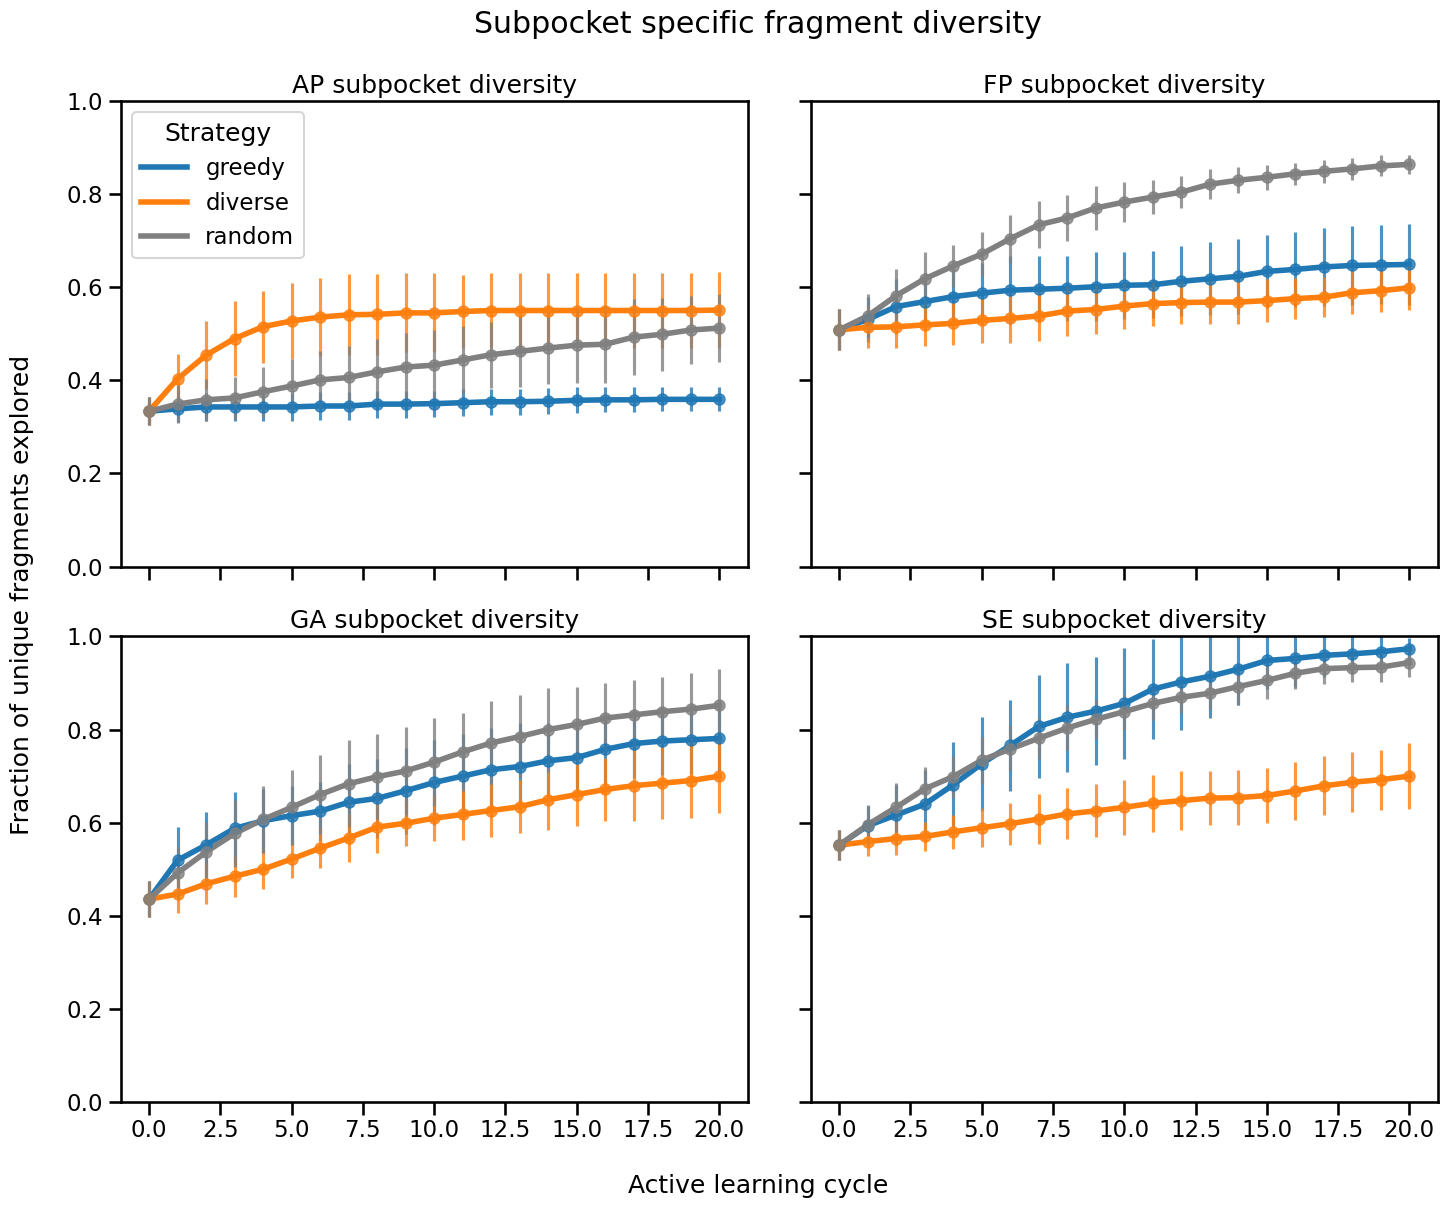

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(17, 13), sharex=True, sharey=True)

for index, (pocket, ax) in enumerate(zip(SUBPOCKETS, axes.flatten())):
    for strategy in STRATEGIES:
        values = subpocket_curves[strategy][:, index, :]
        mean, sd = values.mean(axis=0), values.std(axis=0, ddof=1)
        x = range(len(mean))
        ax.errorbar(x, mean, yerr=sd, fmt="o", color=COLORS[strategy], markersize=8,
                    capsize=0, alpha=0.8)
        ax.plot(x, mean, color=COLORS[strategy], linewidth=4, label=strategy)
    ax.set_ylim(0, 1)
    ax.set_title(f"{pocket} subpocket diversity")

axes[0][0].legend(title="Strategy", loc="upper left")
fig.text(0.5, 0.04, "Active learning cycle", ha="center")
fig.text(0.06, 0.5, "Fraction of unique fragments explored", va="center", rotation="vertical")
fig.suptitle("Subpocket specific fragment diversity", y=0.95)
plt.subplots_adjust(wspace=0.1, hspace=0.15)
plt.savefig(FIGURE_FOLDER / "subpocket_diversity_clustered10.svg", format="svg", bbox_inches="tight")
plt.show()

In [60]:
rows = []
for strategy in STRATEGIES:
    final = subpocket_curves[strategy][:, :, -1]        # runs x subpockets
    for index, pocket in enumerate(SUBPOCKETS):
        rows.append({"strategy": strategy, "subpocket": pocket,
                     "mean": final[:, index].mean().round(3),
                     "sd": final[:, index].std(ddof=1).round(3)})
pd.DataFrame(rows).pivot(index="subpocket", columns="strategy", values=["mean", "sd"])

mean                    sd              
strategy  diverse greedy random diverse greedy random
subpocket                                            
AP          0.551  0.359  0.512   0.081  0.026  0.073
FP          0.599  0.649  0.864   0.047  0.086  0.020
GA          0.700  0.781  0.852   0.080  0.073  0.077
SE          0.700  0.974  0.944   0.071  0.024  0.032

## AP fragment coverage

Of the AP fragments that appear in the best 50, 100 and 500 ligands, how many were seen
during exploration. Bars are the mean over the five runs, error bars one standard
deviation, and the number under each bar is the mean count of fragments found.

In [61]:
top_fragments = [an.top_fragments_per_subpocket(sorted_affs, n_top=n) for n in TOP_NUMS]

coverage_mean, coverage_sd, count_mean, count_sd = {}, {}, {}, {}
for strategy in STRATEGIES:
    shares, counts = [], []
    for seen in selected_fragments[strategy]:        # one entry per run
        per_top = [an.fragment_coverage(top, seen, subpocket="AP") for top in top_fragments]
        shares.append([share for share, _ in per_top])
        counts.append([count for _, count in per_top])
    shares, counts = np.array(shares), np.array(counts)
    coverage_mean[strategy] = shares.mean(axis=0)
    coverage_sd[strategy] = shares.std(axis=0, ddof=1)
    count_mean[strategy] = counts.mean(axis=0)
    count_sd[strategy] = counts.std(axis=0, ddof=1)

# how many distinct AP fragments actually occur in each top k
ap_available = [len(top[0]) for top in top_fragments]
print("AP fragments present in the top k:",
      dict(zip([f"top {n}" for n in TOP_NUMS], ap_available)))

AP fragments present in the top k: {'top 50': 12, 'top 100': 17, 'top 500': 26}


In [62]:
def ap_of(frag_ids):
    """The AP fragment of a ligand; frag_ids are stored sorted, so AP comes first."""
    return frag_ids.split(",")[0]


seen_anywhere, in_top_hit, ap_available = {}, {}, []
for k in TOP_NUMS:
    top_ligands = {frag for frag, _ in sorted_affs[:k]}
    available = {ap_of(frag) for frag in top_ligands}
    ap_available.append(len(available))
    for strategy, by_seed in runs.items():
        loose, strict = [], []
        for _, df in sorted(by_seed.items()):
            found = set(df.frag_ids)
            loose.append(len({ap_of(frag) for frag in found} & available))
            strict.append(len({ap_of(frag) for frag in found & top_ligands}))
        seen_anywhere.setdefault(strategy, []).append(loose)
        in_top_hit.setdefault(strategy, []).append(strict)

seen_anywhere = {s: np.array(v) for s, v in seen_anywhere.items()}   # (top k, runs)
in_top_hit = {s: np.array(v) for s, v in in_top_hit.items()}
print("AP fragments present in the top k:",
      dict(zip([f"top {n}" for n in TOP_NUMS], ap_available)))

AP fragments present in the top k: {'top 50': 12, 'top 100': 17, 'top 500': 26}


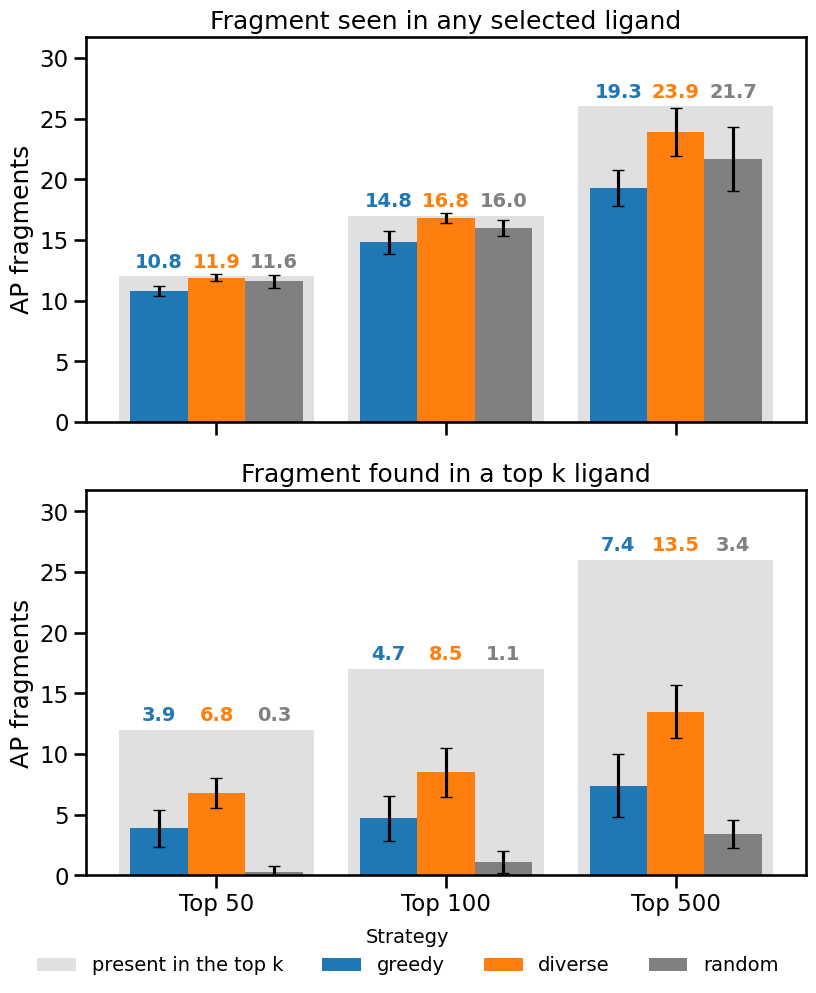

In [63]:
labels = [f"Top {n}" for n in TOP_NUMS]
x = np.arange(len(labels))
width = 0.25

# stacked rather than side by side, so it fits one column of a two column layout
fig, axes = plt.subplots(2, 1, figsize=(8.5, 10), sharex=True, sharey=True)
panels = [(axes[0], seen_anywhere, "Fragment seen in any selected ligand"),
          (axes[1], in_top_hit, "Fragment found in a top k ligand")]

for ax, values, title in panels:
    ax.bar(x, ap_available, width=0.85, color="0.88", zorder=0, label="present in the top k")
    for offset, strategy in zip((-width, 0, width), STRATEGIES):
        mean = values[strategy].mean(axis=1)
        sd = values[strategy].std(axis=1, ddof=1)
        bars = ax.bar(x + offset, mean, width, yerr=sd, capsize=4,
                      color=COLORS[strategy], label=strategy, zorder=2)
        # above the grey ceiling bar, so every label in a group sits at the same height
        for bar, found, ceiling in zip(bars, mean, ap_available):
            ax.text(bar.get_x() + bar.get_width() / 2, ceiling + 0.4,
                    f"{found:.1f}", ha="center", va="bottom", fontsize=14,
                    color=COLORS[strategy], fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_title(title)
    ax.set_ylim(0, max(ap_available) * 1.22)
    ax.set_ylabel("AP fragments")

# one legend below both panels, outside the axes, so it never covers a label
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, title="Strategy", loc="lower center",
           ncol=4, fontsize=14, title_fontsize=14, frameon=False,
           bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig(FIGURE_FOLDER / "ap_fragments_seen_vs_found_clustered10.svg",
            format="svg", bbox_inches="tight")
plt.show()

In [64]:
rows = []
for index, k in enumerate(TOP_NUMS):
    for strategy in STRATEGIES:
        rows.append({
            "top k": k,
            "strategy": strategy,
            "available": ap_available[index],
            "seen anywhere": round(seen_anywhere[strategy][index].mean(), 1),
            "in a top k hit": round(in_top_hit[strategy][index].mean(), 1),
            "sd": round(in_top_hit[strategy][index].std(ddof=1), 1),
        })
pd.DataFrame(rows).set_index(["top k", "strategy"])

available  seen anywhere  in a top k hit   sd
top k strategy                                               
50    greedy           12           10.8             3.9  1.5
      diverse          12           11.9             6.8  1.2
      random           12           11.6             0.3  0.5
100   greedy           17           14.8             4.7  1.8
      diverse          17           16.8             8.5  2.0
      random           17           16.0             1.1  0.9
500   greedy           26           19.3             7.4  2.6
      diverse          26           23.9            13.5  2.2
      random           26           21.7             3.4  1.2

## AP fragments of the best ligands that were never explored

Which AP fragments appear in the top 100 ligands but were not seen by any run, and how much
of that part of the space they account for.

In [65]:
top100_ap = top_fragments[1][0]            # {AP fragment: how often in the top 100}

for strategy in STRATEGIES:
    seen_any = set().union(*(set(seen[0]) for seen in selected_fragments[strategy]))
    missing = {frag: n for frag, n in top100_ap.items() if frag not in seen_any}
    share = sum(missing.values()) / sum(top100_ap.values())
    print(f"{strategy:<9} {len(missing):>2} of {len(top100_ap)} AP fragments never explored "
          f"by any run, covering {share:.1%} of the top 100 ligands")
    if missing:
        worst = sorted(missing.items(), key=lambda kv: -kv[1])[:5]
        print("            most common missed:", ", ".join(f"{f} ({n})" for f, n in worst))

greedy     0 of 17 AP fragments never explored by any run, covering 0.0% of the top 100 ligands
diverse    0 of 17 AP fragments never explored by any run, covering 0.0% of the top 100 ligands
random     0 of 17 AP fragments never explored by any run, covering 0.0% of the top 100 ligands


## Which AP fragments the top k hits sit on

The coverage numbers above say *how many* AP fragments a run reached. These tables say
*which ones*, and how many top k ligands it found on each.

This is the strict reading again: a fragment counts for a run only when the run selected a
ligand that is itself in the overall top k, not merely a ligand that happens to share the
fragment.

In [66]:
def ap_fragments_in_hits(df, top_ligands):
    """{AP fragment: the top k ligands of this run that are built on it}."""
    per_ap = {}
    for frag_ids in set(df.frag_ids) & top_ligands:
        per_ap.setdefault(ap_of(frag_ids), []).append(frag_ids)
    return per_ap


rows = []
for k in TOP_NUMS:
    top_ligands = {frag for frag, _ in sorted_affs[:k]}
    for strategy in STRATEGIES:
        for seed, df in sorted(runs[strategy].items()):
            for ap, ligands in sorted(ap_fragments_in_hits(df, top_ligands).items()):
                rows.append({
                    "strategy": strategy,
                    "seed": seed,
                    "top k": k,
                    "AP fragment": ap,
                    "ligands found": len(ligands),
                    # kept so any number in the tables below can be traced to its ligands
                    "ligands": ";".join(sorted(ligands)),
                })

ap_found = pd.DataFrame(rows)
ap_found.to_csv(FIGURE_FOLDER / "ap_fragments_top_k.csv", index=False)
print(f"{len(ap_found)} rows, written to {FIGURE_FOLDER / 'ap_fragments_top_k.csv'}")
ap_found.head()

496 rows, written to /Users/paulakramer/Documents/PHD/KinFragLib/KinaseActiveLearning/notebooks/../Results/all_seeds_2026-10-28-16-00/ap_fragments_top_k.csv


,strategy,seed,top k,AP fragment,ligands found,ligands
0,greedy,0,50,AP_25,2,"AP_25,FP_51,SE_52;AP_25,FP_89,GA_43"
1,greedy,0,50,AP_35,1,"AP_35,FP_36,SE_64"
2,greedy,0,50,AP_36,16,"AP_36,GA_23,SE_87;AP_36,GA_27,SE_64;AP_36,GA_5..."
3,greedy,0,50,AP_37,2,"AP_37,FP_24,SE_50;AP_37,FP_24,SE_90"
4,greedy,0,50,AP_64,4,"AP_64,GA_50,SE_17;AP_64,GA_50,SE_21;AP_64,GA_5..."


### The reference: AP fragments the top k ligands are built from

The most any run could find on each fragment.

In [67]:
reference = {}
for k in TOP_NUMS:
    counts = pd.Series([ap_of(frag) for frag, _ in sorted_affs[:k]]).value_counts()
    reference[k] = counts
    print(f"top {k}: {len(counts)} AP fragments over {k} ligands")
    print("   " + ", ".join(f"{ap}: {n}" for ap, n in counts.items()))
    print()

top 50: 12 AP fragments over 50 ligands
   AP_36: 22, AP_64: 9, AP_25: 4, AP_7: 3, AP_37: 2, AP_58: 2, AP_53: 2, AP_35: 2, AP_55: 1, AP_79: 1, AP_24: 1, AP_99: 1

top 100: 17 AP fragments over 100 ligands
   AP_36: 28, AP_64: 19, AP_7: 10, AP_58: 10, AP_25: 7, AP_35: 5, AP_53: 4, AP_37: 3, AP_51: 3, AP_24: 2, AP_99: 2, AP_55: 2, AP_79: 1, AP_8: 1, AP_66: 1, AP_98: 1, AP_71: 1

top 500: 26 AP fragments over 500 ligands
   AP_64: 100, AP_36: 89, AP_7: 62, AP_58: 53, AP_25: 34, AP_53: 29, AP_35: 27, AP_51: 21, AP_55: 18, AP_71: 12, AP_37: 11, AP_99: 11, AP_24: 8, AP_8: 8, AP_66: 4, AP_67: 2, AP_2: 2, AP_98: 1, AP_3: 1, AP_48: 1, AP_63: 1, AP_96: 1, AP_43: 1, AP_79: 1, AP_33: 1, AP_6: 1



### Per run: ligands found and how many fragments they sit on

In [68]:
summary = []
for strategy in STRATEGIES:
    for seed in sorted(runs[strategy]):
        row = {"strategy": strategy, "seed": seed}
        for k in TOP_NUMS:
            part = ap_found[(ap_found.strategy == strategy) & (ap_found.seed == seed)
                            & (ap_found["top k"] == k)]
            row[f"top{k} ligands"] = int(part["ligands found"].sum())
            row[f"top{k} APs"] = len(part)
        summary.append(row)

summary = pd.DataFrame(summary)
summary

,strategy,seed,top50 ligands,top50 APs,top100 ligands,top100 APs,top500 ligands,top500 APs
0,greedy,0,28,6,48,6,147,9
1,greedy,1,24,5,33,5,119,11
2,greedy,2,30,3,50,4,171,5
3,greedy,3,24,3,43,4,149,5
4,greedy,4,25,2,37,2,116,5
5,greedy,5,25,4,43,5,143,8
6,greedy,6,32,5,49,6,156,9
7,greedy,7,9,3,25,5,90,7
8,greedy,8,28,6,53,8,163,11
9,greedy,9,24,2,36,2,124,4


### One strategy at a time: fragments as rows, seeds as columns

Seeds run from the best to the worst, so a fragment that only the good runs reach shows up
as a block on the left. Greedy is close to all or nothing per fragment, diverse is graded.

In [69]:
RANK_BY = 100       # the top k used to order the seeds and to build the matrix
N_GROUP = 3         # how many seeds count as the best and as the worst


def ap_matrix(strategy, k=RANK_BY):
    """AP fragments as rows, seeds as columns, ordered from the best run to the worst."""
    part = ap_found[(ap_found.strategy == strategy) & (ap_found["top k"] == k)]
    seeds = sorted(runs[strategy])
    totals = (part.groupby("seed")["ligands found"].sum()
              .reindex(seeds, fill_value=0).sort_values(ascending=False))
    matrix = part.pivot_table(index="AP fragment", columns="seed",
                              values="ligands found", aggfunc="sum", fill_value=0)
    # every fragment of the top k as a row, every seed as a column, missing ones as 0
    matrix = matrix.reindex(index=reference[k].index,
                            columns=totals.index).fillna(0).astype(int)
    matrix.insert(0, f"in top {k}", reference[k])
    return matrix


ap_matrix("greedy")

seed,in top 100,8,2,6,0,3,5,4,9,1,7
AP_36,28,20,27,26,21,22,21,27,26,18,0
AP_64,19,10,14,10,10,11,10,10,10,3,11
AP_7,10,8,0,8,8,0,8,0,0,8,0
AP_58,10,8,8,0,0,8,0,0,0,0,9
AP_25,7,0,0,0,3,0,0,0,0,0,0
AP_35,5,2,0,0,3,0,1,0,0,1,0
AP_53,4,0,0,0,0,0,0,0,0,0,3
AP_37,3,3,0,3,3,0,3,0,0,3,0
AP_51,3,1,1,0,0,2,0,0,0,0,0
AP_24,2,0,0,1,0,0,0,0,0,0,0


In [70]:
ap_matrix("diverse")

seed,in top 100,9,4,8,5,6,7,2,0,1,3
AP_36,28,17,9,13,9,5,8,4,3,0,1
AP_64,19,8,1,6,4,4,3,2,2,0,0
AP_7,10,6,5,4,3,5,0,4,4,3,0
AP_58,10,6,8,4,5,0,6,6,0,0,0
AP_25,7,0,0,0,0,1,1,0,1,0,0
AP_35,5,1,1,1,1,1,1,2,1,1,1
AP_53,4,2,1,2,3,2,3,0,0,2,0
AP_37,3,0,3,0,0,3,0,0,3,2,0
AP_51,3,1,1,0,0,0,0,1,0,0,0
AP_24,2,0,1,0,0,1,0,0,1,0,0


### The same two tables as LaTeX

`booktabs` is the only package needed. Each table is also written next to the results as
`ap_matrix_<strategy>_top100.tex`, ready for `\input{}`.

In [81]:
def tex_escape(text):
    """LaTeX safe version of a fragment name like AP_36."""
    return str(text).replace("_", r"\_")


def ap_matrix_latex(strategy, k=RANK_BY, zero="--", save=True):
    """The ap_matrix of one strategy as a booktabs LaTeX table."""
    matrix = ap_matrix(strategy, k)
    reference_column = f"in top {k}"
    seeds = [column for column in matrix.columns if column != reference_column]

    def cell(value):
        # zeros are written as a dash, so the fragments a run never reached stay blank
        return zero if value == 0 else str(value)

    lines = [
        r"\begin{table}[htbp]",
        r"  \centering",
        r"  \small",
        r"  \setlength{\tabcolsep}{4pt}",
        rf"  \caption{{AP fragments of the top {k} ligands recovered by the "
        rf"\textbf{{{strategy}}} strategy. The second column is the most any run could "
        rf"find on that fragment; the remaining columns are the ten seeds, ordered from "
        rf"the run that recovered the most top {k} ligands to the one that recovered the "
        rf"fewest. {zero} means the run found none.}}",
        rf"  \label{{tab:ap-matrix-{strategy}}}",
        rf"  \begin{{tabular}}{{l r @{{\hskip 8pt}} {'r' * len(seeds)}}}",
        r"    \toprule",
        rf"    AP fragment & in top {k} & \multicolumn{{{len(seeds)}}}{{c}}{{seed}} \\",
        rf"    \cmidrule(lr){{3-{len(seeds) + 2}}}",
        r"     & & " + " & ".join(str(seed) for seed in seeds) + r" \\",
        r"    \midrule",
    ]
    for fragment, row in matrix.iterrows():
        values = " & ".join(cell(row[seed]) for seed in seeds)
        lines.append(f"    {tex_escape(fragment)} & {row[reference_column]} & {values} " + r"\\")
    lines += [r"    \bottomrule", r"  \end{tabular}", r"\end{table}"]

    table = "\n".join(lines)
    if save:
        path = FIGURE_FOLDER / f"ap_matrix_{strategy}_top{k}.tex"
        path.write_text(table + "\n")
        print(f"% written to {path}")
    return table


print(ap_matrix_latex("greedy"))
print()
print(ap_matrix_latex("diverse"))

% written to /Users/paulakramer/Documents/PHD/KinFragLib/KinaseActiveLearning/notebooks/../Results/all_seeds_2026-10-28-16-00/ap_matrix_greedy_top100.tex
\begin{table}[htbp]
  \centering
  \small
  \setlength{\tabcolsep}{4pt}
  \caption{AP fragments of the top 100 ligands recovered by the \textbf{greedy} strategy. The second column is the most any run could find on that fragment; the remaining columns are the ten seeds, ordered from the run that recovered the most top 100 ligands to the one that recovered the fewest. -- means the run found none.}
  \label{tab:ap-matrix-greedy}
  \begin{tabular}{l r @{\hskip 8pt} rrrrrrrrrr}
    \toprule
    AP fragment & in top 100 & \multicolumn{10}{c}{seed} \\
    \cmidrule(lr){3-12}
     & & 8 & 2 & 6 & 0 & 3 & 5 & 4 & 9 & 1 & 7 \\
    \midrule
    AP\_36 & 28 & 20 & 27 & 26 & 21 & 22 & 21 & 27 & 26 & 18 & -- \\
    AP\_64 & 19 & 10 & 14 & 10 & 10 & 11 & 10 & 10 & 10 & 3 & 11 \\
    AP\_7 & 10 & 8 & -- & 8 & 8 & -- & 8 & -- & -- & 8 & -- \\
    AP\_

## What the leading AP fragments look like

The structures behind the fragment names, drawn from the fragment library so the picture
and the counts above cannot drift apart.

In [78]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit.Chem.Draw import rdMolDraw2D

import utils

PATH_FRAGMENT_LIB = HERE / ".." / "data" / "fragment_library_custom_filtered"
fragment_library = utils.read_fragment_library(PATH_FRAGMENT_LIB)

N_FRAGMENTS = 4     # how many of the leading AP fragments to show
top_aps = list(reference[RANK_BY].index[:N_FRAGMENTS])


def fragment_row(name):
    """The fragment library entry for a name like 'AP_36'."""
    pocket, index = name.split("_")
    return fragment_library[pocket].loc[int(index)]


fragment_smiles = pd.DataFrame([
    {
        "AP fragment": name,
        f"ligands in top {RANK_BY}": int(reference[RANK_BY][name]),
        "share": f"{reference[RANK_BY][name] / RANK_BY:.0%}",
        "SMILES": fragment_row(name).smiles,
        "with attachment points": fragment_row(name).smiles_dummy,
        # which other subpockets this fragment can be grown into
        "connects to": " ".join(
            sorted(set(fragment_row(name).atom_subpockets.split(" ")) - {"AP"})
        ),
    }
    for name in top_aps
])
fragment_smiles

,AP fragment,ligands in top 100,share,SMILES,with attachment points,connects to
0,AP_36,28,28%,Nc1cnccn1,*c1cnc(N)c(*)n1,GA SE
1,AP_64,19,19%,c1ccc2ncccc2c1,*c1ccc2ncc(*)c(*)c2c1,GA SE
2,AP_7,10,10%,Nc1ncccc1O,*Oc1cc(*)cnc1N,FP SE
3,AP_58,10,10%,c1ccc2occc2c1,*c1ccc2occ(*)c2c1,FP GA


saved top_ap_fragments.svg and top_ap_fragments.png in /Users/paulakramer/Documents/PHD/KinFragLib/KinaseActiveLearning/notebooks/../Results/all_seeds_2026-10-28-16-00


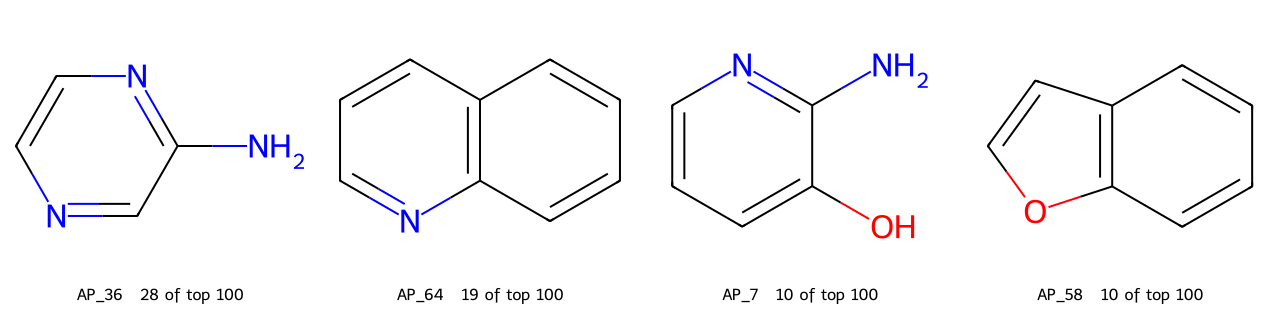

In [79]:
def draw_fragments(names, with_dummies=False, size=320, per_row=4):
    """Draws the fragments and saves an .svg for figures and a .png to look at."""
    mols = []
    for name in names:
        row = fragment_row(name)
        mol = Chem.RemoveHs(Chem.Mol(row.ROMol_dummy if with_dummies else row.ROMol))
        # the library molecules carry 3D coordinates from their complexes, which draw
        # as overlapping tangles, so lay them out flat first
        AllChem.Compute2DCoords(mol)
        mols.append(mol)
    legends = [f"{name}   {reference[RANK_BY][name]} of top {RANK_BY}" for name in names]

    stem = "top_ap_fragments" + ("_with_attachment_points" if with_dummies else "")
    n_rows = (len(mols) + per_row - 1) // per_row
    for drawer, suffix in ((rdMolDraw2D.MolDraw2DSVG, ".svg"),
                           (rdMolDraw2D.MolDraw2DCairo, ".png")):
        canvas = drawer(size * min(per_row, len(mols)), size * n_rows, size, size)
        canvas.drawOptions().legendFontSize = 20
        canvas.DrawMolecules(mols, legends=legends)
        canvas.FinishDrawing()
        drawing = canvas.GetDrawingText()
        with open(FIGURE_FOLDER / f"{stem}{suffix}",
                  "wb" if isinstance(drawing, bytes) else "w") as handle:
            handle.write(drawing)
    print(f"saved {stem}.svg and {stem}.png in {FIGURE_FOLDER}")
    return Draw.MolsToGridImage(mols, legends=legends, molsPerRow=per_row,
                                subImgSize=(size, size))


draw_fragments(top_aps)

saved top_ap_fragments_with_attachment_points.svg and top_ap_fragments_with_attachment_points.png in /Users/paulakramer/Documents/PHD/KinFragLib/KinaseActiveLearning/notebooks/../Results/all_seeds_2026-10-28-16-00


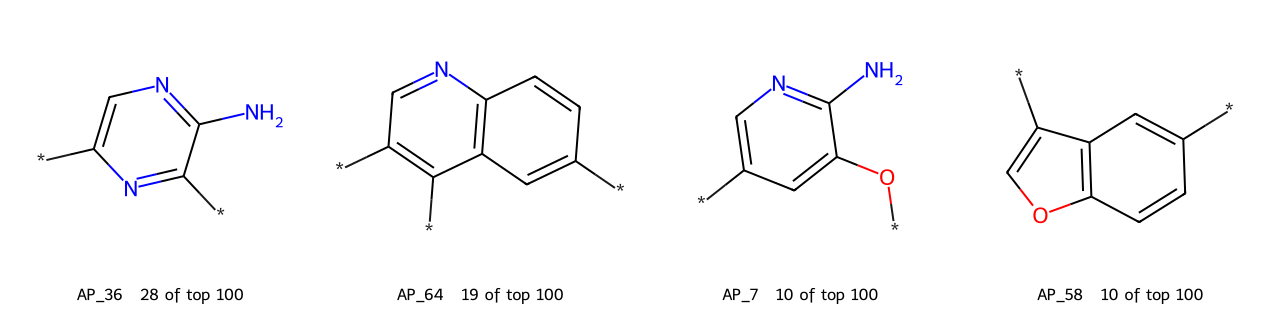

In [80]:
# the same fragments with the attachment points, where the FP, GA and SE fragments go
draw_fragments(top_aps, with_dummies=True)

saved top_ap_fragments_with_attachment_points.svg and top_ap_fragments_with_attachment_points.png in /Users/paulakramer/Documents/PHD/KinFragLib/KinaseActiveLearning/notebooks/../Results/all_seeds_2026-10-28-16-00


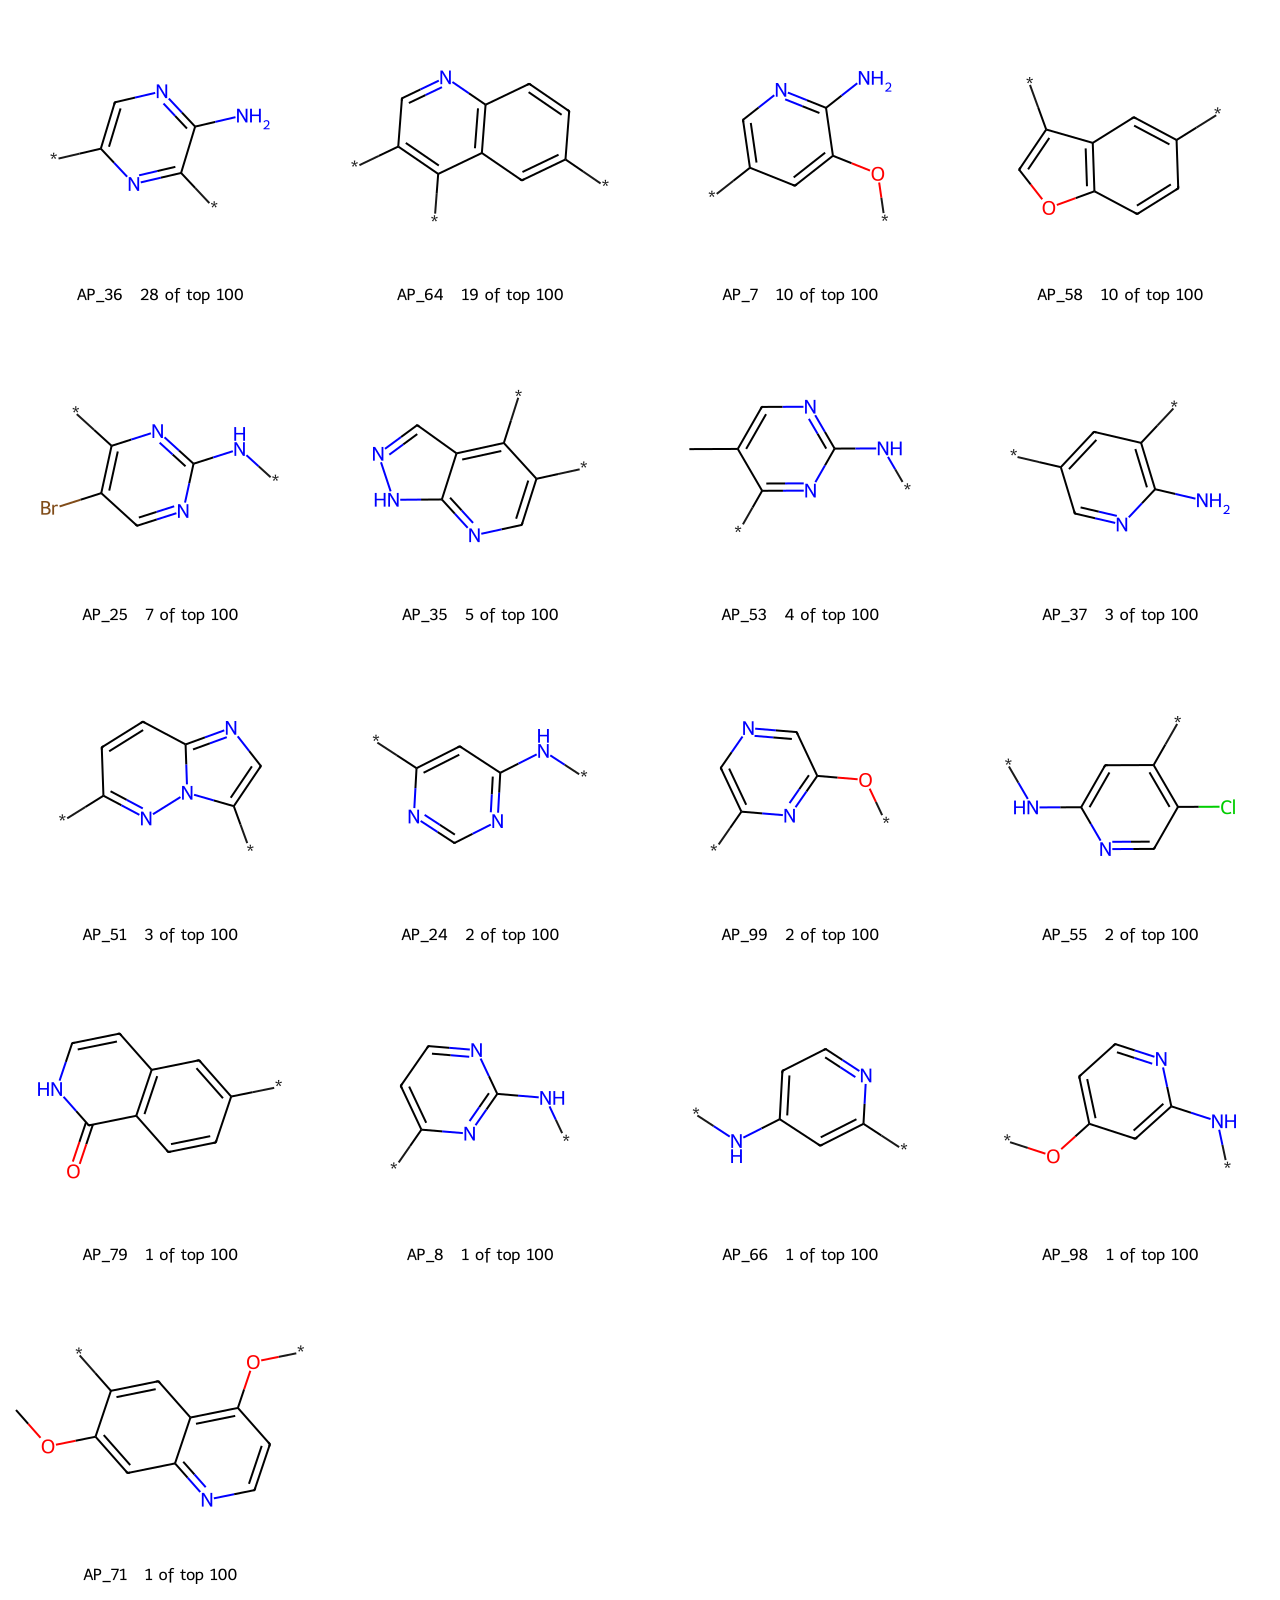

In [77]:
draw_fragments(top_aps, with_dummies=True)